In [26]:
pip install --upgrade earthaccess

Note: you may need to restart the kernel to use updated packages.


In [1]:
import geopandas as gpd
import earthaccess
import os

# SETTINGS

shapefile = r"C:\NISAR\chennai_155.shp"
output_dir = r"C:\NISAR"

start_date = "2026-06-03"
end_date   = "2026-07-03"

os.makedirs(output_dir, exist_ok=True)

# READ DELHI SHAPEFILE

gdf = gpd.read_file(shapefile)

print("Original CRS:", gdf.crs)

# Convert to geographic coordinates
gdf = gdf.to_crs("EPSG:4326")

# Combine Delhi polygons
delhi = gdf.geometry.union_all()

# Bounding box
minx, miny, maxx, maxy = delhi.bounds

print("\nDelhi bounding box:")
print(minx, miny, maxx, maxy)

# EARTHDATA LOGIN

print("\nLogging into NASA Earthdata...")

auth = earthaccess.login()

print("Earthdata login successful.")

# SEARCH NISAR PROVISIONAL GCOV

print("\nSearching NISAR PROVISIONAL GCOV...")

results = earthaccess.search_data(
    short_name="NISAR_L2_GCOV_PROVISIONAL_V1",
    temporal=(start_date, end_date),
    bounding_box=(minx, miny, maxx, maxy),
    count=100
)

print("\nNumber of scenes found:", len(results))

# DISPLAY RESULTS

for i, r in enumerate(results, 1):

    print("\n------------------------------------")
    print("Scene:", i)
    print("Granule:", r)

C:\Users\Dell\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Original CRS: EPSG:4326

Delhi bounding box:
80.1857831854032 12.9672590490807 80.3069299 13.1480077308886

Logging into NASA Earthdata...


Enter your Earthdata Login username:  Pradip_1994
Enter your Earthdata password:  ········


Earthdata login successful.

Searching NISAR PROVISIONAL GCOV...

Number of scenes found: 4

------------------------------------
Scene: 1
Granule: Collection: {'ShortName': 'NISAR_L2_GCOV_PROVISIONAL_V1', 'Version': '1'}
Spatial coverage: {'GranuleLocalities': ['Land', 'Asia'], 'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Latitude': 12.06603, 'Longitude': 80.44372}, {'Latitude': 14.21002, 'Longitude': 79.92424}, {'Latitude': 13.65777, 'Longitude': 77.61031}, {'Latitude': 11.52396, 'Longitude': 78.1506}, {'Latitude': 12.06603, 'Longitude': 80.44372}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2026-06-20T00:16:30.000000Z', 'EndingDateTime': '2026-06-20T00:17:05.999342Z'}}
Size(MB): 4875.721804618835
Data: ['https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_PROVISIONAL_V1/NISAR_L2_PR_GCOV_023_084_A_008_4005_DHDH_A_20260620T001630_20260620T001705_P05023_N_F_J_001/NISAR_L2_PR_GCOV_023_084_A_008_4005_DHDH_A_20260620T001

In [ ]:
### download all scene

In [ ]:
print("\nStarting NISAR download...")

files = earthaccess.download(
    results,
    local_path=output_dir
)

print("\nDownload completed.")
print("Files downloaded:", len(files))


Starting NISAR download...


QUEUEING TASKS | :   0%|          | 0/4 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
### download single scene

In [ ]:
import earthaccess
import os

# Output folder
download_dir = r"C:\NISAR"
os.makedirs(download_dir, exist_ok=True)

# --------------------------------------------------
# DOWNLOAD ONLY ONE NISAR FILE
# --------------------------------------------------

if len(results) > 0:

    single_scene = results[0]

    print("\nDownloading ONE NISAR scene...")
    print("Granule:")
    print(single_scene)

    downloaded = earthaccess.download(
        [single_scene],          # ONLY ONE FILE
        local_path=download_dir
    )

    print("\n================================")
    print("Download completed!")
    print("Downloaded file:")
    print(downloaded)

else:

    print("No NISAR scenes found.")


Granule:
Collection: {'ShortName': 'NISAR_L2_GCOV_PROVISIONAL_V1', 'Version': '1'}
Spatial coverage: {'GranuleLocalities': ['Land', 'Asia'], 'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Latitude': 12.06603, 'Longitude': 80.44372}, {'Latitude': 14.21002, 'Longitude': 79.92424}, {'Latitude': 13.65777, 'Longitude': 77.61031}, {'Latitude': 11.52396, 'Longitude': 78.1506}, {'Latitude': 12.06603, 'Longitude': 80.44372}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2026-06-20T00:16:30.000000Z', 'EndingDateTime': '2026-06-20T00:17:05.999342Z'}}
Size(MB): 4875.721804618835
Data: ['https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_PROVISIONAL_V1/NISAR_L2_PR_GCOV_023_084_A_008_4005_DHDH_A_20260620T001630_20260620T001705_P05023_N_F_J_001/NISAR_L2_PR_GCOV_023_084_A_008_4005_DHDH_A_20260620T001630_20260620T001705_P05023_N_F_J_001.h5']


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
### download second scene and etc (just change the (second_scene = results[1]), insted of one use 2,3,4,5,6,7.....)

In [ ]:
import earthaccess
import os

download_dir = r"C:\NISAR"
os.makedirs(download_dir, exist_ok=True)

# SECOND NISAR SCENE
second_scene = results[1]

print("Downloading second NISAR scene...")
print(second_scene)

downloaded = earthaccess.download(
    [second_scene],          # only the second scene
    local_path=download_dir
)

print("\nDownload completed!")
print(downloaded)

Collection: {'ShortName': 'NISAR_L2_GCOV_PROVISIONAL_V1', 'Version': '1'}
Spatial coverage: {'GranuleLocalities': ['Land', 'Asia'], 'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Latitude': 14.16148, 'Longitude': 78.85247}, {'Latitude': 12.0766, 'Longitude': 78.34934}, {'Latitude': 11.54288, 'Longitude': 80.6069}, {'Latitude': 13.61836, 'Longitude': 81.12853}, {'Latitude': 14.16148, 'Longitude': 78.85247}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2026-06-24T13:11:03.000000Z', 'EndingDateTime': '2026-06-24T13:11:37.999342Z'}}
Size(MB): 5550.565647125244
Data: ['https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_PROVISIONAL_V1/NISAR_L2_PR_GCOV_023_149_D_082_4005_DHDH_A_20260624T131103_20260624T131137_P05023_N_F_J_001/NISAR_L2_PR_GCOV_023_149_D_082_4005_DHDH_A_20260624T131103_20260624T131137_P05023_N_F_J_001.h5']


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
### visualization

In [1]:
import os
import glob

# Change this to your NISAR download folder
data_folder = r"C:\NISAR"

files = glob.glob(os.path.join(data_folder, "**", "*"), recursive=True)

for f in files:
    if os.path.isfile(f):
        print(f)

C:\NISAR\chennai_155.cpg
C:\NISAR\chennai_155.dbf
C:\NISAR\chennai_155.prj
C:\NISAR\chennai_155.qmd
C:\NISAR\chennai_155.shp
C:\NISAR\chennai_155.shx
C:\NISAR\partial_55pz_iq3
C:\NISAR\partial_5o1lu5fd
C:\NISAR\partial_7zgbf5zr
C:\NISAR\partial_hmh5xvyi
C:\NISAR\partial_lih3bfr3
C:\NISAR\partial_q6lsh6vu
C:\NISAR\partial_r9pt8yim
C:\NISAR\partial_wxehjo_k
C:\NISAR\partial_zrgqy_2q
C:\NISAR\data\NISAR_L2_PR_GCOV_023_084_A_008_4005_DHDH_A_20260620T001630_20260620T001705_P05023_N_F_J_001.h5


In [2]:
### Find the HDF5 structure

In [3]:
import h5py
import os

h5_file = r"C:\NISAR\data\NISAR_L2_PR_GCOV_023_084_A_008_4005_DHDH_A_20260620T001630_20260620T001705_P05023_N_F_J_001.h5"

with h5py.File(h5_file, "r") as f:

    def print_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(
                f"DATASET: {name} | "
                f"shape={obj.shape} | "
                f"dtype={obj.dtype}"
            )
        else:
            print(f"GROUP:   {name}")

    f.visititems(print_structure)

GROUP:   science
GROUP:   science/LSAR
GROUP:   science/LSAR/GCOV
GROUP:   science/LSAR/GCOV/grids
GROUP:   science/LSAR/GCOV/grids/frequencyA
DATASET: science/LSAR/GCOV/grids/frequencyA/HHHH | shape=(33120, 33768) | dtype=float32
DATASET: science/LSAR/GCOV/grids/frequencyA/HVHV | shape=(33120, 33768) | dtype=float32
DATASET: science/LSAR/GCOV/grids/frequencyA/inputDataExceptionMask | shape=(33120, 33768) | dtype=uint8
DATASET: science/LSAR/GCOV/grids/frequencyA/listOfCovarianceTerms | shape=(2,) | dtype=|S4
DATASET: science/LSAR/GCOV/grids/frequencyA/listOfPolarizations | shape=(2,) | dtype=|S2
DATASET: science/LSAR/GCOV/grids/frequencyA/mask | shape=(33120, 33768) | dtype=uint8
DATASET: science/LSAR/GCOV/grids/frequencyA/numberOfLooks | shape=(33120, 33768) | dtype=float32
DATASET: science/LSAR/GCOV/grids/frequencyA/numberOfSubSwaths | shape=() | dtype=uint8
DATASET: science/LSAR/GCOV/grids/frequencyA/projection | shape=() | dtype=uint32
DATASET: science/LSAR/GCOV/grids/frequencyA/rt

In [4]:
### Automatically find SAR datasets

In [5]:
import h5py

with h5py.File(h5_file, "r") as f:

    sar_datasets = []

    def find_sar(name, obj):

        if isinstance(obj, h5py.Dataset):

            name_lower = name.lower()

            if any(
                pol in name_lower
                for pol in ["hh", "hv", "vv", "vh"]
            ):
                sar_datasets.append(name)

    f.visititems(find_sar)

print("\nSAR datasets found:")
print("=" * 70)

for i, path in enumerate(sar_datasets):
    print(i, path)


SAR datasets found:
0 science/LSAR/GCOV/grids/frequencyA/HHHH
1 science/LSAR/GCOV/grids/frequencyA/HVHV
2 science/LSAR/GCOV/grids/frequencyB/HHHH
3 science/LSAR/GCOV/grids/frequencyB/HVHV
4 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HH/differentialDelay
5 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HH/differentialPhase
6 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HH/rfiLikelihood
7 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HH/scaleFactor
8 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HH/scaleFactorSlope
9 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HV/differentialDelay
10 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HV/differentialPhase
11 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HV/rfiLikelihood
12 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HV/scaleFactor
13 science/LSAR/GCOV/metadata/calibrationInformation/frequencyA/HV/scaleF

HDF5 file opened successfully

Dataset:
<HDF5 dataset "HVHV": shape (33120, 33768), type "<f4">
Shape: (33120, 33768)
Data type: float32

Number of sampled pixels: 250871
2%: 0.0
98%: 0.12833023


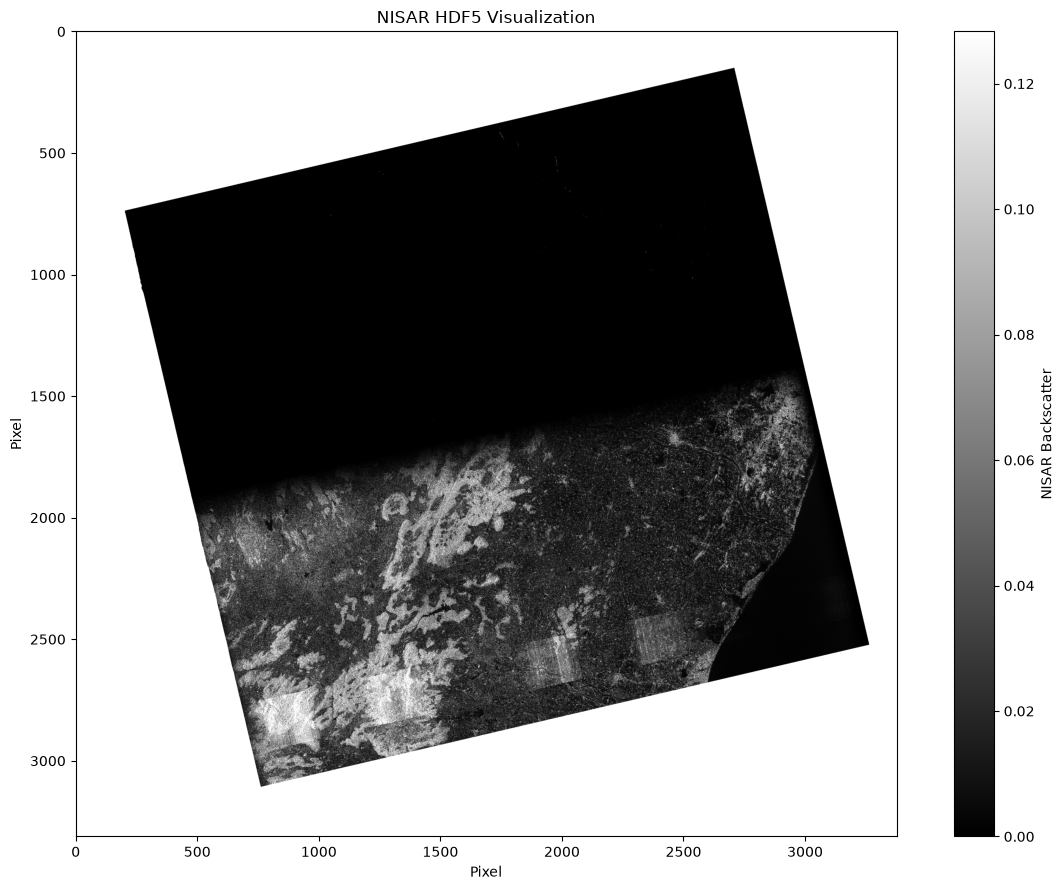

In [9]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. H5 FILE
# ---------------------------------------------------------
h5_file = r"C:\NISAR\data\NISAR_L2_PR_GCOV_023_084_A_008_4005_DHDH_A_20260620T001630_20260620T001705_P05023_N_F_J_001.h5"

# ---------------------------------------------------------
# 2. OPEN HDF5
# ---------------------------------------------------------
with h5py.File(h5_file, "r") as f:

    print("HDF5 file opened successfully")

    # -----------------------------------------------------
    # CHANGE THIS DATASET PATH IF NEEDED
    # -----------------------------------------------------
    dataset_path = "science/LSAR/GCOV/grids/frequencyA/HVHV"

    dset = f[dataset_path]

    print("\nDataset:")
    print(dset)

    print("Shape:", dset.shape)
    print("Data type:", dset.dtype)

    # -----------------------------------------------------
    # 3. READ ONLY A SMALL SAMPLE
    # -----------------------------------------------------
    rows, cols = dset.shape

    # Read every 50th pixel
    step = 50

    sample = dset[::step, ::step]

    # Convert to float32
    sample = np.asarray(sample, dtype=np.float32)

    # Remove invalid values
    sample = sample[np.isfinite(sample)]

    print("\nNumber of sampled pixels:", sample.size)

    # -----------------------------------------------------
    # 4. CALCULATE PERCENTILE FROM SAMPLE
    # -----------------------------------------------------
    vmin = np.percentile(sample, 2)
    vmax = np.percentile(sample, 98)

    print("2%:", vmin)
    print("98%:", vmax)

    # -----------------------------------------------------
    # 5. READ FULL DATASET
    # -----------------------------------------------------
    # IMPORTANT:
    # This may still require several GB of RAM.
    #
    # Instead of reading the entire image, create
    # a downsampled visualization.
    
    display_step = 10

    data = dset[::display_step, ::display_step]

    data = np.asarray(data, dtype=np.float32)

    # Remove invalid values
    data[~np.isfinite(data)] = np.nan

    # -----------------------------------------------------
    # 6. DISPLAY
    # -----------------------------------------------------
    plt.figure(figsize=(12, 9))

    plt.imshow(
        data,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    plt.colorbar(label="NISAR Backscatter")
    plt.title("NISAR HDF5 Visualization")
    plt.xlabel("Pixel")
    plt.ylabel("Pixel")

    plt.tight_layout()
    plt.show()